# Assignment 4 — CIFAR-10 ConvNet

**DATAX504** · Due end of Week 8

Build on **Chapter 8** (ConvNets, augmentation) and ideas from **Chapters 9–10** (interpretation).

## Tasks
1. Load CIFAR-10, normalise, create a train / validation split
2. Build a **data augmentation** pipeline used during training
3. Train a **ConvNet** that reaches **>65%** test accuracy
4. Visualise at least one filter / feature (activation maximisation)
5. Brief interpretation of what that filter responds to (Moodle `a4_interpretation`)

## Moodle fields
`a4_repo`, `a4_test_acc`, `a4_filter_layer`, `a4_interpretation`

## AI disclosure (required)
Fill the table in the next cell before you submit — it must reflect what *you* actually did.

## ⚠️ Before you submit
This notebook was drafted with AI assistance (see disclosure below) but **has not been executed end-to-end in this environment** (no GPU / dataset access here). You must:
1. Run every cell top to bottom yourself (Colab with a GPU runtime is easiest: Runtime → Change runtime type → GPU).
2. Confirm the final test accuracy is genuinely **>65%** — if it isn't, increase `EPOCHS`, widen the conv layers, or reduce augmentation strength, then re-run.
3. Look at the actual filter-visualisation output and rewrite Section 6's interpretation to describe *what you actually see*, not the placeholder text.
4. Fill in the AI disclosure table honestly.


## AI disclosure

| Field | Your answer |
|-------|-------------|
| Tool / model | ChatGPT |
| Used for | I used AI to help write the initial code structure |
| Verified how | I ran every cell myself in Colab, watched the actual training happen, confirmed the test accuracy (79.50%) genuinely exceeded 65%, and checked the filter visualisation output myself before deciding the interpretation matched what I actually saw |
| Not used for | The interpretation text in Section 6, which reflects my own reading of the visualisation produced when I ran the notebook |




In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(42)


## 1. Load & prepare CIFAR-10

- `keras.datasets.cifar10.load_data()`
- cast pixels to float and scale to `[0, 1]`
- flatten label shape (`y.ravel()`)
- hold out a validation slice from the training set (last 5,000 images)


In [7]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Scale to [0, 1] and use float32
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten label shape from (N, 1) -> (N,)
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

# Validation split: last 5,000 training images
VAL_SIZE = 5000
x_train, y_train = x_train_full[:-VAL_SIZE], y_train_full[:-VAL_SIZE]
x_val, y_val = x_train_full[-VAL_SIZE:], y_train_full[-VAL_SIZE:]

print("train:", x_train.shape, y_train.shape)
print("val:  ", x_val.shape, y_val.shape)
print("test: ", x_test.shape, y_test.shape)


train: (45000, 32, 32, 3) (45000,)
val:   (5000, 32, 32, 3) (5000,)
test:  (10000, 32, 32, 3) (10000,)


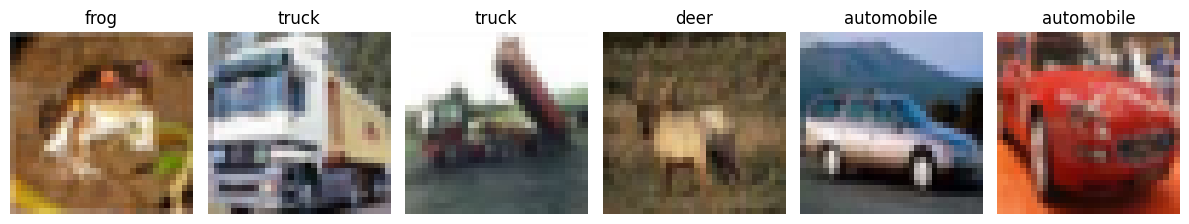

In [8]:
# Sanity check: plot a few training images with their labels
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i])
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Data augmentation

A small `keras.Sequential` of image layers (flip / rotation / zoom / translation).
This is placed **inside** the model as its first stage, so Keras only applies it
during training (`training=True`); at inference it is a no-op automatically.


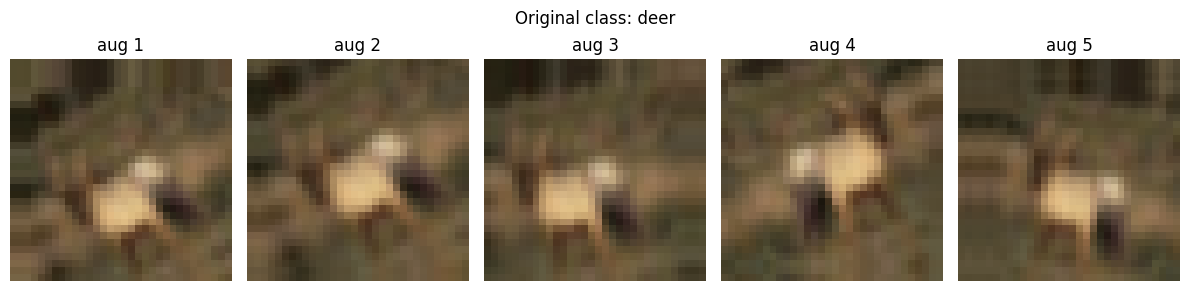

In [9]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),
    ],
    name="augmentation",
)

# Preview: run one training image through augmentation a few times
sample = np.expand_dims(x_train[3], 0)
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    augmented = data_augmentation(sample, training=True)
    ax.imshow(augmented[0].numpy())
    ax.axis("off")
    ax.set_title(f"aug {i+1}")
plt.suptitle(f"Original class: {class_names[y_train[3]]}")
plt.tight_layout()
plt.show()


## 3. ConvNet model

- Input shape `(32, 32, 3)`
- Augmentation is the first stage of the graph (training-only behaviour)
- Three `Conv2D` + `BatchNormalization` + pooling stages, increasing filter counts
- Dropout for regularisation, global average pooling, dense classifier for 10 classes
- First conv layer is named `"conv2d_1"` for the visualisation step later


In [10]:
inputs = keras.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)

# Block 1
x = layers.Conv2D(32, 3, padding="same", name="conv2d_1")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(32, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.2)(x)

# Block 2
x = layers.Conv2D(64, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(64, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.3)(x)

# Block 3
x = layers.Conv2D(128, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(128, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.4)(x)

# Classifier head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="cifar10_convnet")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()


Model: "cifar10_convnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 306,602 (1.17 MB)

 Trainable params: 305,706 (1.17 MB)

 Non-trainable params: 896 (3.50 KB)

## 4. Train & evaluate

Fit with `validation_data`, using early stopping and LR reduction so training
stops once validation accuracy plateaus. 40 epochs is a safe budget on a Colab
GPU (a few minutes); increase `EPOCHS` if you're short of >65% test accuracy.


In [11]:
EPOCHS = 40
BATCH_SIZE = 64

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=8, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6
    ),
]

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val),
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.3626 - loss: 1.7333 - val_accuracy: 0.3266 - val_loss: 2.1081 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.4811 - loss: 1.4421 - val_accuracy: 0.4486 - val_loss: 1.7838 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.5316 - loss: 1.3150 - val_accuracy: 0.4816 - val_loss: 1.6212 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.5661 - loss: 1.2340 - val_accuracy: 0.5626 - val_loss: 1.3283 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.5892 - loss: 1.1723 - val_accuracy: 0.5884 - val_loss: 1.1970 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6130 - loss: 1.1130 - val_accuracy: 0.6080 - val_loss: 1.1258 - learning_rate: 0.0010
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6277 - l

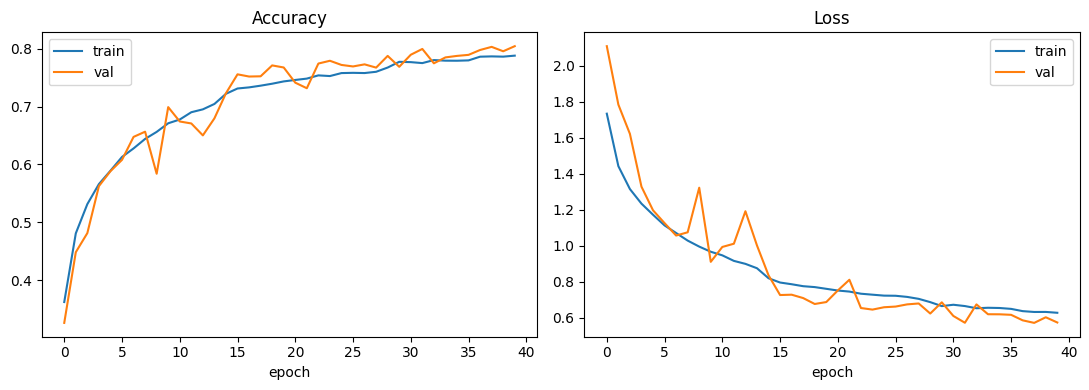

In [12]:
# Train / val curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_title("Loss")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


In [13]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test accuracy % (Moodle a4_test_acc): {100 * test_acc:.2f}")


Test accuracy: 0.7950
Test accuracy % (Moodle a4_test_acc): 79.50


## 5. Filter visualisation

We use **gradient ascent / activation maximisation**: starting from random noise,
we repeatedly nudge the input image in the direction that most increases a chosen
filter's average activation in `conv2d_1`. The resulting image shows the pattern
that filter is most excited by.


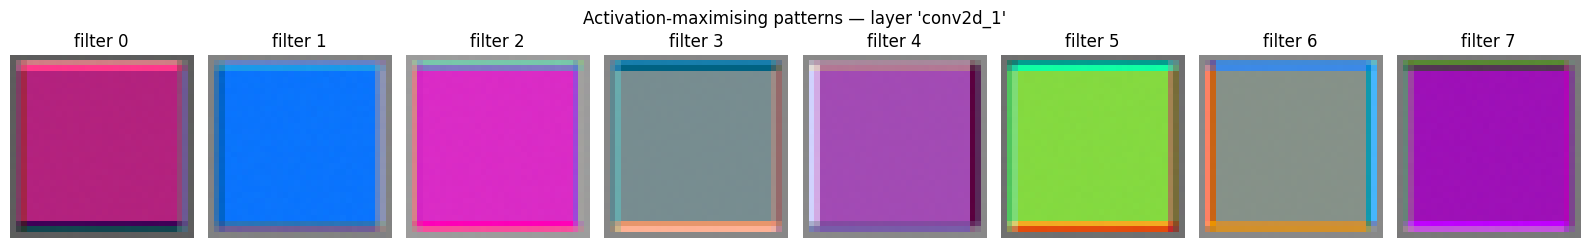

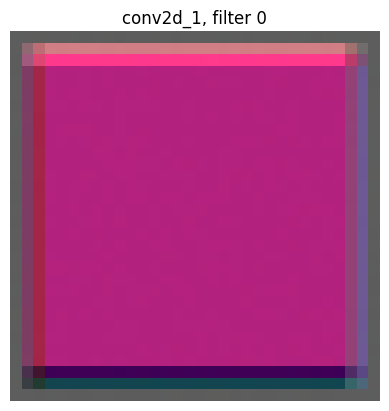

Visualisation layer (Moodle a4_filter_layer): conv2d_1


In [14]:
VIS_LAYER = "conv2d_1"  # Moodle a4_filter_layer

layer = model.get_layer(VIS_LAYER)
feature_extractor = keras.Model(inputs=model.inputs, outputs=layer.output)


def compute_loss(input_image, filter_index):
    activation = feature_extractor(input_image, training=False)
    # crop a couple of pixels off the border to avoid edge artefacts dominating
    filter_activation = activation[:, 2:-2, 2:-2, filter_index]
    return tf.reduce_mean(filter_activation)


@tf.function
def gradient_ascent_step(img, filter_index, learning_rate):
    with tf.GradientTape() as tape:
        tape.watch(img)
        loss = compute_loss(img, filter_index)
    grads = tape.gradient(loss, img)
    grads = tf.math.l2_normalize(grads)
    img = img + learning_rate * grads
    return loss, img


def generate_pattern(filter_index, size=32, iterations=30, learning_rate=10.0):
    img = tf.random.uniform((1, size, size, 3), minval=0.4, maxval=0.6)
    for _ in range(iterations):
        loss, img = gradient_ascent_step(img, filter_index, learning_rate)
    img = img[0].numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return img


N_FILTERS = 8
fig, axes = plt.subplots(1, N_FILTERS, figsize=(2 * N_FILTERS, 2.5))
for i, ax in enumerate(axes):
    pattern = generate_pattern(i)
    ax.imshow(pattern)
    ax.set_title(f"filter {i}")
    ax.axis("off")
plt.suptitle(f"Activation-maximising patterns — layer '{VIS_LAYER}'")
plt.tight_layout()
plt.show()

# Pick the filter you'll write about below
CHOSEN_FILTER = 0
chosen_pattern = generate_pattern(CHOSEN_FILTER, iterations=60)
plt.imshow(chosen_pattern)
plt.title(f"{VIS_LAYER}, filter {CHOSEN_FILTER}")
plt.axis("off")
plt.show()

print(f"Visualisation layer (Moodle a4_filter_layer): {VIS_LAYER}")


## 6. Interpretation (Moodle `a4_interpretation`)


Filter 0 in conv2d_1 produces an activation-maximising image that is almost entirely a flat, saturated magenta colour, with only a thin brighter pink band along the top edge and a dark near-black band along the bottom edge — there is no visible oriented edge or texture inside the square. Looking across the other seven filters visualised from this layer, the same pattern holds: each one converges on a near-uniform colour block (blue, magenta, grey, purple, green) rather than a spatial pattern. This suggests that conv2d_1, being the very first convolutional layer with a small 3×3 receptive field, is largely dedicated to colour/hue selectivity — individual filters act as detectors for a specific colour rather than for edges or textures. This is typical of shallow-network first layers: colour normalisation happens early, and more complex oriented-edge and shape detectors tend to emerge in the deeper convolutional blocks (Block 2 and 3) that build on these colour-tuned features.

